In [1]:
import sys

print("Python path:", sys.executable)
print("Environment is working!")

Python path: d:\st-ml\medical-insurance-prediction\.venv\Scripts\python.exe
Environment is working!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Medical Insurance Cost Prediction

## Problem Statement
The objective is to predict annual medical insurance charges
based on personal information such as age, sex, BMI,
number of children, smoking habits, and region.

## Machine Learning Type
- Learning: Supervised Learning
- Problem: Regression
- Target Variable: charges
- Evaluation Metrics: MAE, RMSE, R2 Score

In [4]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
# Statistical summary
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
# Check missing values
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [7]:
# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 1


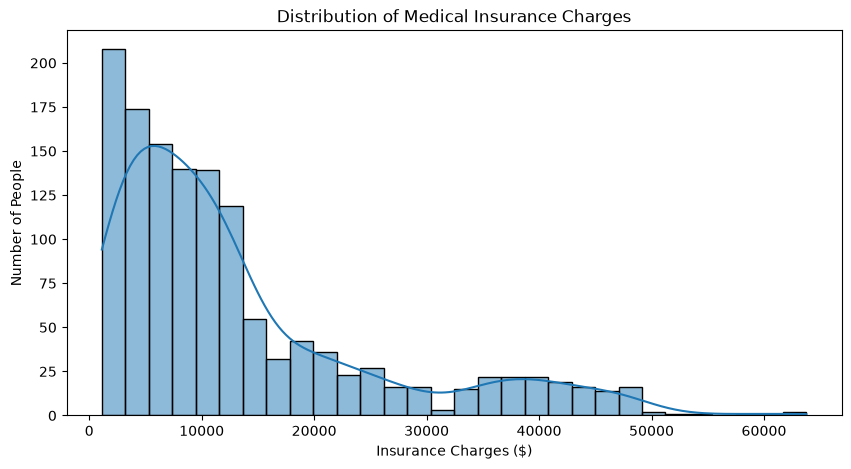

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["charges"],
    bins=30,
    kde=True
)

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Insurance Charges ($)")
plt.ylabel("Number of People")

plt.show()

In [9]:
print("Charges Skewness:", df["charges"].skew())

Charges Skewness: 1.5158796580240388


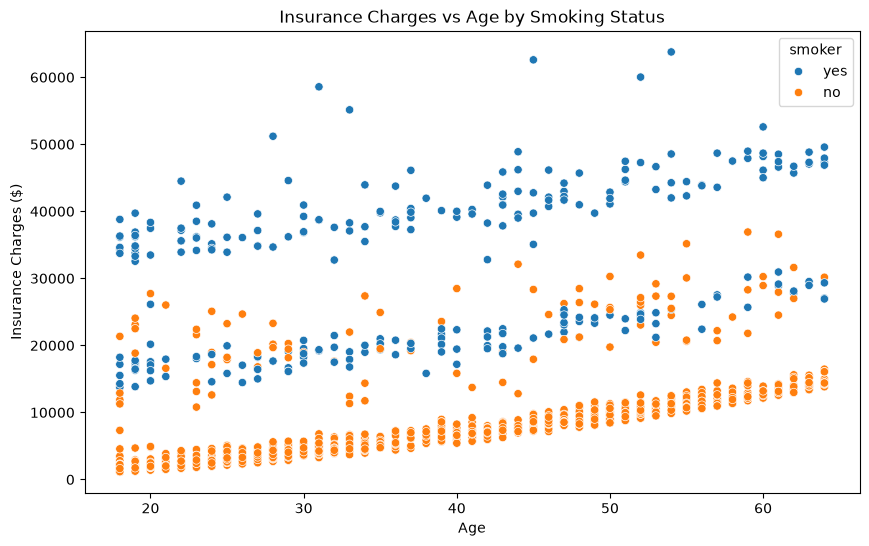

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker"
)

plt.title("Insurance Charges vs Age by Smoking Status")
plt.xlabel("Age")
plt.ylabel("Insurance Charges ($)")

plt.show()

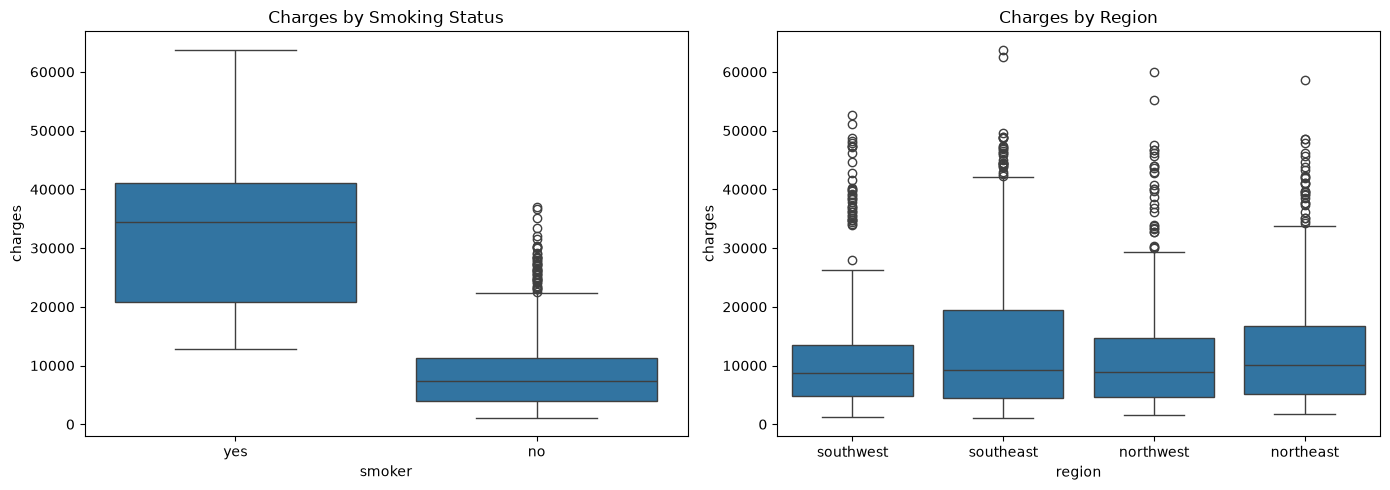

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="charges",
    ax=axes[0]
)

axes[0].set_title("Charges by Smoking Status")

sns.boxplot(
    data=df,
    x="region",
    y="charges",
    ax=axes[1]
)

axes[1].set_title("Charges by Region")

plt.tight_layout()
plt.show()

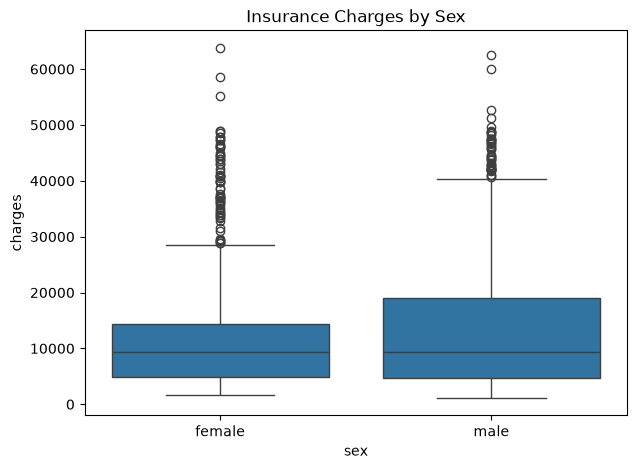

In [12]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="charges"
)

plt.title("Insurance Charges by Sex")
plt.show()

In [13]:
# Remove duplicate records
df_clean = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("Clean dataset:", df_clean.shape)

# Separate input and target
X = df_clean.drop("charges", axis=1)
y = df_clean["charges"]

# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)

Original dataset: (1338, 7)
Clean dataset: (1337, 7)
Training records: (1069, 6)
Testing records: (268, 6)


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "age",
    "bmi",
    "children"
]

categorical_features = [
    "sex",
    "smoker",
    "region"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),

        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# Baseline model
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

# Linear Regression pipeline
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [17]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

def evaluate_model(model, X_data, y_data):

    predictions = model.predict(X_data)

    mae = mean_absolute_error(y_data, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_data, predictions)
    )

    r2 = r2_score(y_data, predictions)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [18]:
results = []

for name, model in [
    ("Dummy Regressor", baseline),
    ("Linear Regression", linear_model)
]:

    train_metrics = evaluate_model(
        model, X_train, y_train
    )

    test_metrics = evaluate_model(
        model, X_test, y_test
    )

    results.append({
        "Model": name,
        "Train MAE": train_metrics["MAE"],
        "Test MAE": test_metrics["MAE"],
        "Train RMSE": train_metrics["RMSE"],
        "Test RMSE": test_metrics["RMSE"],
        "Train R2": train_metrics["R2"],
        "Test R2": test_metrics["R2"]
    })

comparison = pd.DataFrame(results)

comparison.round(3)

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Dummy Regressor,8786.695,9861.798,11701.054,13612.426,0.00,-0.008
1,Linear Regression,4181.902,4177.046,6081.107,5956.343,0.73,0.807


In [19]:
# Transform training and testing data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert to NumPy arrays
X_train_np = np.asarray(X_train_processed, dtype=float)
X_test_np = np.asarray(X_test_processed, dtype=float)

y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

print("Training shape:", X_train_np.shape)
print("Testing shape:", X_test_np.shape)

Training shape: (1069, 11)
Testing shape: (268, 11)


In [20]:
# Transform training and testing data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert to NumPy arrays
X_train_np = np.asarray(X_train_processed, dtype=float)
X_test_np = np.asarray(X_test_processed, dtype=float)

y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

print("Training shape:", X_train_np.shape)
print("Testing shape:", X_test_np.shape)

Training shape: (1069, 11)
Testing shape: (268, 11)


In [22]:
def gradient_descent(X, y, learning_rate=0.01, epochs=1000):

    n, features = X.shape

    weights = np.zeros(features)
    bias = 0

    history = []

    for epoch in range(epochs):

        predictions = X @ weights + bias

        errors = predictions - y

        dw = (2/n) * (X.T @ errors)
        db = (2/n) * np.sum(errors)

        weights -= learning_rate * dw
        bias -= learning_rate * db

        mse = np.mean(errors ** 2)
        history.append(mse)

    return weights, bias, history

In [23]:
weights, bias, history = gradient_descent(
    X_train_np,
    y_train_np,
    learning_rate=0.01,
    epochs=1000
)

print("Gradient Descent completed!")
print("Weights:", weights)
print("Bias:", bias)

Gradient Descent completed!
Weights: [ 3473.57149831  1915.9571111    638.59336753  4470.90877265
  4386.13151839 -7060.818066   15917.85835705  2678.76262017
  2263.55946696  1898.78614142  2015.9320625 ]
Bias: 8857.040291048257


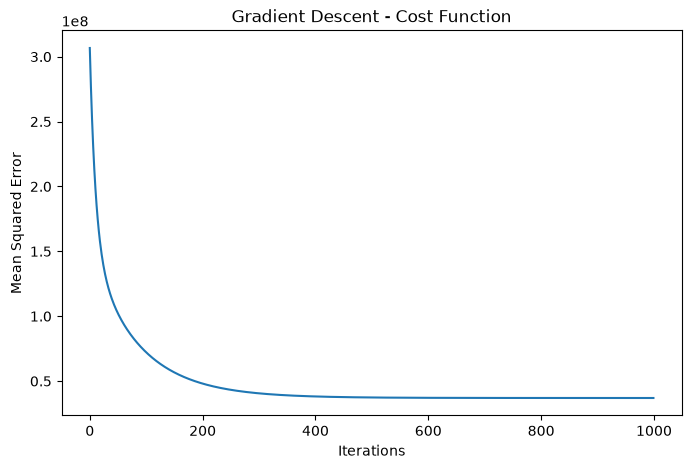

In [24]:
plt.figure(figsize=(8,5))

plt.plot(history)

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent - Cost Function")

plt.show()

In [25]:
gd_predictions = X_test_np @ weights + bias

gd_rmse = np.sqrt(
    mean_squared_error(y_test_np, gd_predictions)
)

print("Gradient Descent Test RMSE:", gd_rmse)
print("Sklearn Linear Regression Test RMSE:",
      evaluate_model(linear_model, X_test, y_test)["RMSE"])

Gradient Descent Test RMSE: 5968.421616807641
Sklearn Linear Regression Test RMSE: 5956.3428943635845


d:\st-ml\medical-insurance-prediction\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\MEHER RANI\AppData\Local\Temp\ipykernel_17800\3244333525.py:22: RuntimeWarning: overflow encountered in square
  mse = np.mean(errors ** 2)
C:\Users\MEHER RANI\AppData\Local\Temp\ipykernel_17800\3244333525.py:16: RuntimeWarning: overflow encountered in matmul
  dw = (2/n) * (X.T @ errors)
d:\st-ml\medical-insurance-prediction\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\MEHER RANI\AppData\Local\Temp\ipykernel_17800\3244333525.py:12: RuntimeWarning: invalid value encountered in matmul
  predictions = X @ weights + bias
d:\st-ml\medical-insurance-prediction\.venv\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np

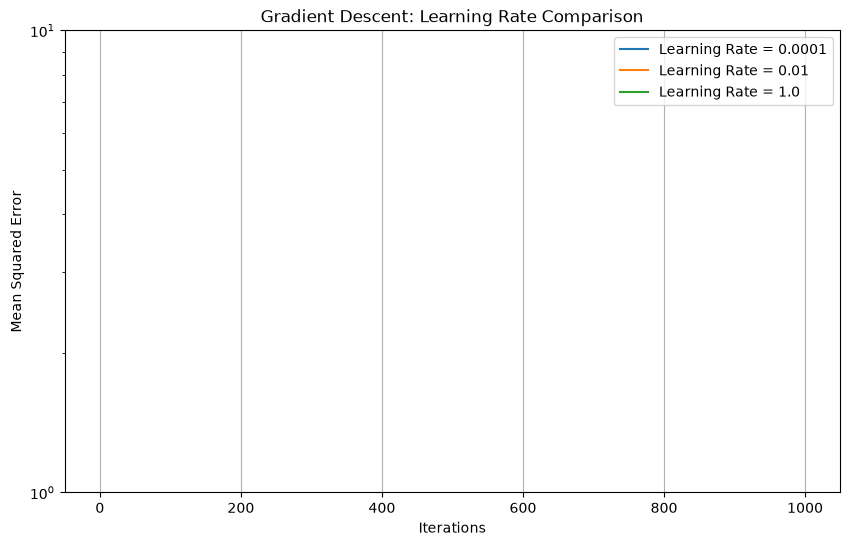

In [26]:
learning_rates = [0.0001, 0.01, 1.0]

plt.figure(figsize=(10, 6))

for lr in learning_rates:

    w, b, costs = gradient_descent(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    costs = np.array(costs)

    valid = np.isfinite(costs) & (costs > 0)

    plt.plot(
        np.arange(len(costs))[valid],
        costs[valid],
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent: Learning Rate Comparison")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.show()

In [27]:
sklearn_weights = (
    linear_model.named_steps["regressor"].coef_
)

sklearn_bias = (
    linear_model.named_steps["regressor"].intercept_
)

print("Gradient Descent Weights:")
print(weights)

print("\nSklearn Weights:")
print(sklearn_weights)

print("\nGradient Descent Bias:", bias)
print("Sklearn Bias:", sklearn_bias)

print("\nMaximum weight difference:",
      np.max(np.abs(weights - sklearn_weights)))

Gradient Descent Weights:
[ 3473.57149831  1915.9571111    638.59336753  4470.90877265
  4386.13151839 -7060.818066   15917.85835705  2678.76262017
  2263.55946696  1898.78614142  2015.9320625 ]

Sklearn Weights:
[  3472.97555343   1927.82825101    636.5011853      50.771027
    -50.771027   -11538.88229643  11538.88229643    472.45520552
     80.69375073   -366.46441021   -186.68454604]

Gradient Descent Bias: 8857.040291048257
Sklearn Bias: 19963.608258992183

Maximum weight difference: 4478.064230431186


In [28]:
def gradient_descent_safe(X, y, learning_rate, epochs=1000):

    n, features = X.shape

    weights = np.zeros(features)
    bias = 0

    history = []

    for epoch in range(epochs):

        with np.errstate(over="ignore", invalid="ignore"):
            predictions = X @ weights + bias
            errors = predictions - y

            mse = np.mean(errors ** 2)

            if not np.isfinite(mse):
                break

            history.append(mse)

            dw = (2/n) * (X.T @ errors)
            db = (2/n) * np.sum(errors)

            new_weights = weights - learning_rate * dw
            new_bias = bias - learning_rate * db

        if not np.all(np.isfinite(new_weights)) or not np.isfinite(new_bias):
            break

        weights = new_weights
        bias = new_bias

    return weights, bias, history

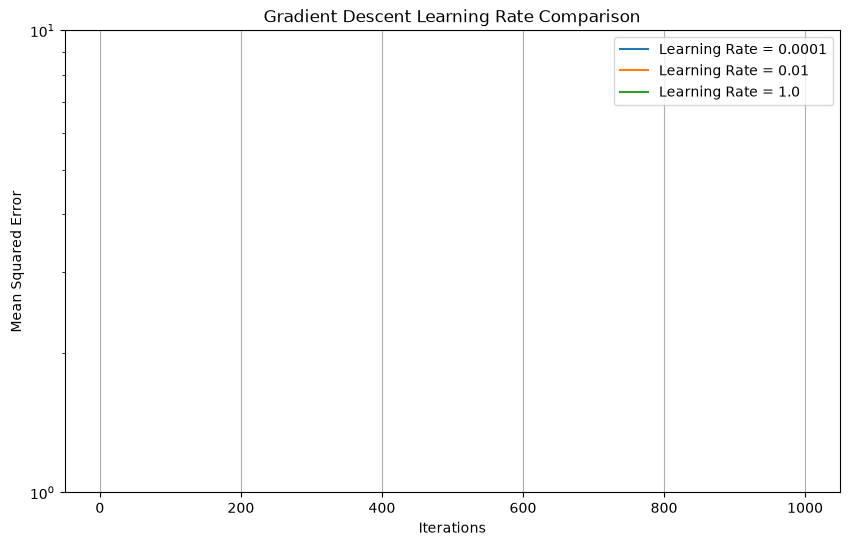

In [29]:
learning_rates = [0.0001, 0.01, 1.0]

plt.figure(figsize=(10, 6))

for lr in learning_rates:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    plt.plot(
        range(len(costs)),
        costs,
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Learning Rate Comparison")

plt.yscale("log")
plt.legend()
plt.grid(True)

plt.show()

In [30]:
for lr in [0.0001, 0.01, 1.0]:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    print("\nLearning rate:", lr)
    print("Iterations completed:", len(costs))
    print("First cost:", costs[0] if costs else "No values")
    print("Last cost:", costs[-1] if costs else "No values")


Learning rate: 0.0001
Iterations completed: 1000
First cost: 306700869.9649415
Last cost: 199729348.16385365

Learning rate: 0.01
Iterations completed: 1000
First cost: 306700869.9649415
Last cost: 36982185.65724714

Learning rate: 1.0
Iterations completed: 251
First cost: 306700869.9649415
Last cost: 3.297683660171429e+304


In [31]:
test_rates = [0.000001, 0.0001, 0.001, 0.01]

for lr in test_rates:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    print(f"\nLearning Rate: {lr}")
    print("Iterations:", len(costs))
    print("Initial Cost:", costs[0] if costs else None)
    print("Final Cost:", costs[-1] if costs else None)


Learning Rate: 1e-06
Iterations: 1000
Initial Cost: 306700869.9649415
Final Cost: 305108714.75474507

Learning Rate: 0.0001
Iterations: 1000
Initial Cost: 306700869.9649415
Final Cost: 199729348.16385365

Learning Rate: 0.001
Iterations: 1000
Initial Cost: 306700869.9649415
Final Cost: 72316476.87216745

Learning Rate: 0.01
Iterations: 1000
Initial Cost: 306700869.9649415
Final Cost: 36982185.65724714


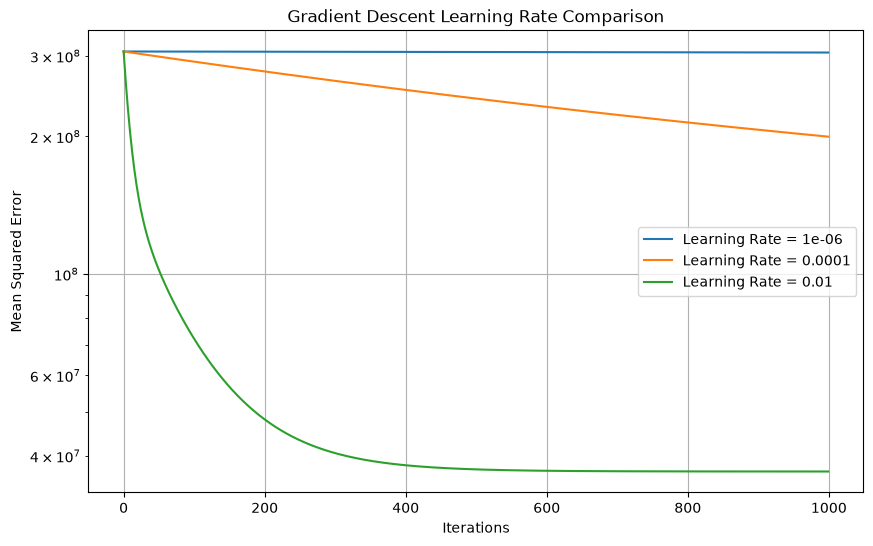

In [32]:
learning_rates = [0.000001, 0.0001, 0.01]

plt.figure(figsize=(10, 6))

for lr in learning_rates:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    plt.plot(
        range(len(costs)),
        costs,
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Learning Rate Comparison")

plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

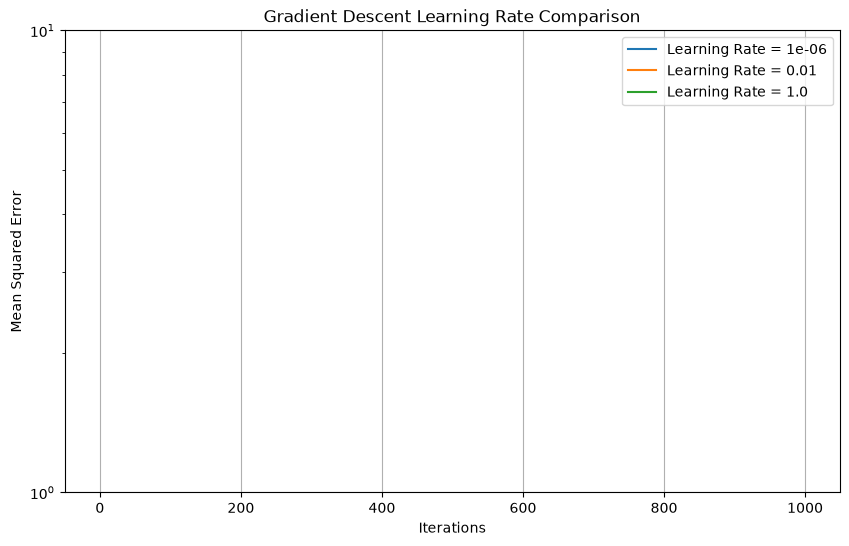

In [33]:
learning_rates = [0.000001, 0.01, 1.0]

plt.figure(figsize=(10, 6))

for lr in learning_rates:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    plt.plot(
        range(len(costs)),
        costs,
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Learning Rate Comparison")

plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
for lr in [0.000001, 0.01, 1.0]:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    print("\nLearning Rate:", lr)
    print("Number of costs:", len(costs))
    print("First 5 costs:", costs[:5])
    print("Last cost:", costs[-1] if costs else "Empty")


Learning Rate: 1e-06
Number of costs: 1000
First 5 costs: [np.float64(306700869.9649415), np.float64(306699269.1236176), np.float64(306697668.2965523), np.float64(306696067.4837457), np.float64(306694466.68519735)]
Last cost: 305108714.75474507

Learning Rate: 0.01
Number of costs: 1000
First 5 costs: [np.float64(306700869.9649415), np.float64(291048889.76312435), np.float64(276754965.71178573), np.float64(263691600.1533226), np.float64(251743442.2755008)]
Last cost: 36982185.65724714

Learning Rate: 1.0
Number of costs: 251
First 5 costs: [np.float64(306700869.9649415), np.float64(2270542822.497221), np.float64(33677514619.927), np.float64(515097726836.04724), np.float64(7893451124287.894)]
Last cost: 3.297683660171429e+304


In [35]:
print("X shape:", X_train_np.shape)
print("Y shape:", y_train_np.shape)

print("X finite:", np.isfinite(X_train_np).all())
print("Y finite:", np.isfinite(y_train_np).all())

X shape: (1069, 11)
Y shape: (1069,)
X finite: True
Y finite: True


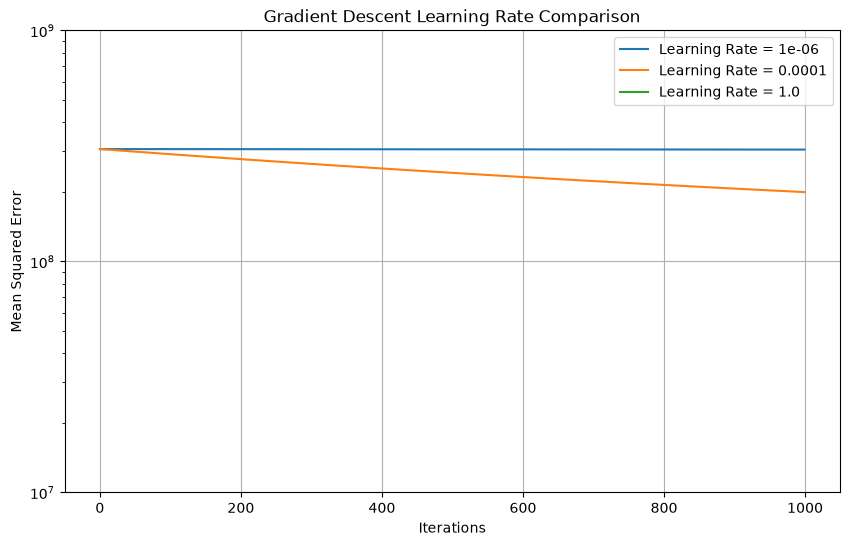

In [36]:
learning_rates = [0.000001, 0.0001, 1.0]

plt.figure(figsize=(10, 6))

for lr in learning_rates:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    costs = np.array(costs)

    # Keep finite, positive values within plotting range
    valid = (
        np.isfinite(costs) &
        (costs > 0) &
        (costs <= 1e9)
    )

    plt.plot(
        np.arange(len(costs))[valid],
        costs[valid],
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Learning Rate Comparison")

plt.yscale("log")
plt.ylim(1e7, 1e9)

plt.legend()
plt.grid(True)
plt.show()

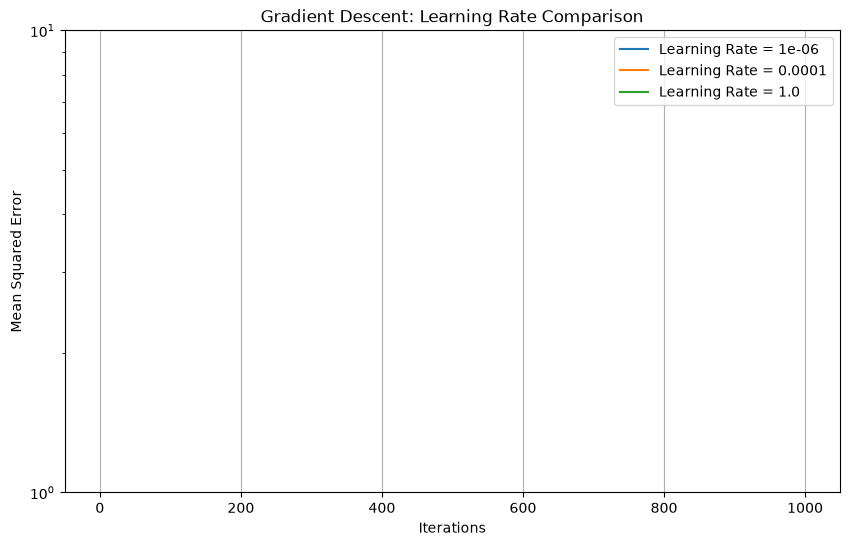

In [37]:
learning_rates = [0.000001, 0.0001, 1.0]

plt.figure(figsize=(10, 6))

for lr in learning_rates:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    costs = np.array(costs)

    valid = np.isfinite(costs) & (costs > 0)

    plt.plot(
        np.arange(len(costs))[valid],
        costs[valid],
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent: Learning Rate Comparison")

plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
for lr in [0.000001, 0.0001, 1.0]:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    print("\nLearning rate:", lr)
    print("Cost count:", len(costs))
    print("First cost:", costs[0] if len(costs) else "Empty")
    print("Last cost:", costs[-1] if len(costs) else "Empty")


Learning rate: 1e-06
Cost count: 1000
First cost: 306700869.9649415
Last cost: 305108714.75474507

Learning rate: 0.0001
Cost count: 1000
First cost: 306700869.9649415
Last cost: 199729348.16385365

Learning rate: 1.0
Cost count: 251
First cost: 306700869.9649415
Last cost: 3.297683660171429e+304


1e-06 Points: 1000
0.0001 Points: 1000
1.0 Points: 251


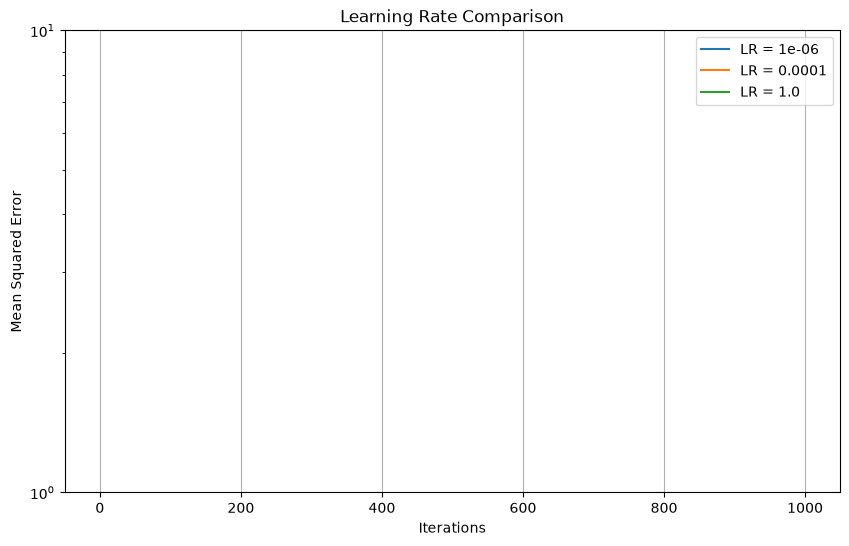

In [39]:
plt.figure(figsize=(10, 6))

for lr in [0.000001, 0.0001, 1.0]:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    costs = np.asarray(costs)

    valid = np.isfinite(costs) & (costs > 0)

    print(lr, "Points:", valid.sum())

    plt.semilogy(
        np.arange(len(costs))[valid],
        costs[valid],
        label=f"LR = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Learning Rate Comparison")
plt.legend()
plt.grid(True)
plt.show()

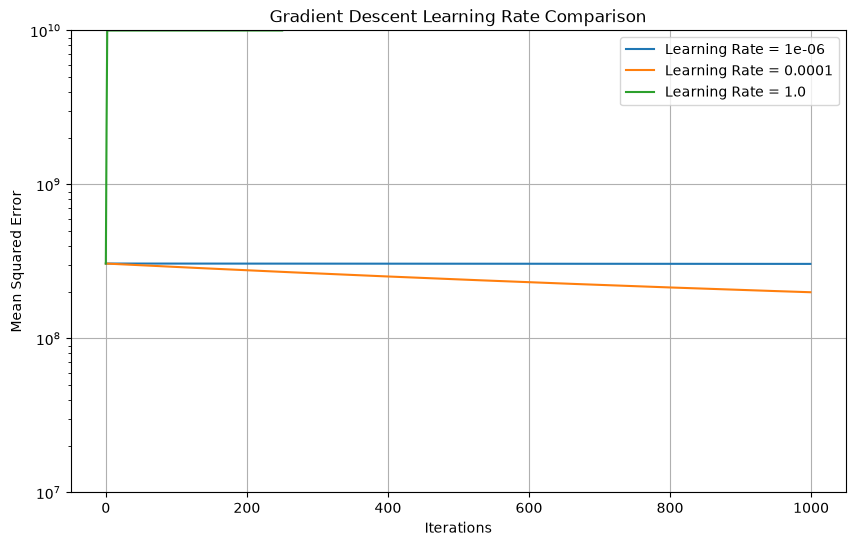

In [40]:
learning_rates = [0.000001, 0.0001, 1.0]

fig, ax = plt.subplots(figsize=(10, 6))

for lr in learning_rates:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    costs = np.asarray(costs)

    valid = np.isfinite(costs) & (costs > 0)

    iterations = np.arange(len(costs))[valid]

    # Clip extreme values only for visualization
    plotted_costs = np.clip(costs[valid], 1e7, 1e10)

    ax.plot(
        iterations,
        plotted_costs,
        label=f"Learning Rate = {lr}"
    )

ax.set_xlabel("Iterations")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Gradient Descent Learning Rate Comparison")

ax.set_yscale("log")
ax.set_ylim(1e7, 1e10)

ax.legend()
ax.grid(True)

plt.show()

In [41]:
for lr in [0.0001, 0.0005, 0.001, 0.002]:

    w, b, costs = gradient_descent_safe(
        X_train_np,
        y_train_np,
        learning_rate=lr,
        epochs=1000
    )

    print(
        f"LR: {lr} | "
        f"Initial: {costs[0]:.2f} | "
        f"Final: {costs[-1]:.2f}"
    )

LR: 0.0001 | Initial: 306700869.96 | Final: 199729348.16
LR: 0.0005 | Initial: 306700869.96 | Final: 102357272.86
LR: 0.001 | Initial: 306700869.96 | Final: 72316476.87
LR: 0.002 | Initial: 306700869.96 | Final: 48160582.91


In [42]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(),
         ["age", "bmi", "children"]),

        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), ["sex", "smoker", "region"])
    ]
)

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Updated model trained!")

Updated model trained!


In [43]:
X_train_np = np.asarray(
    linear_model.named_steps["preprocessor"].transform(X_train),
    dtype=float
)

X_test_np = np.asarray(
    linear_model.named_steps["preprocessor"].transform(X_test),
    dtype=float
)

y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

print("Training shape:", X_train_np.shape)

Training shape: (1069, 8)


In [44]:
weights, bias, history = gradient_descent_safe(
    X_train_np,
    y_train_np,
    learning_rate=0.002,
    epochs=10000
)

print("Training completed!")

Training completed!


In [45]:
sklearn_weights = (
    linear_model.named_steps["regressor"].coef_
)

sklearn_bias = (
    linear_model.named_steps["regressor"].intercept_
)

print("Gradient Descent Weights:")
print(weights)

print("\nSklearn Weights:")
print(sklearn_weights)

print("\nGradient Descent Bias:", bias)
print("Sklearn Bias:", sklearn_bias)

print("\nMaximum Weight Difference:",
      np.max(np.abs(weights - sklearn_weights)))

Gradient Descent Weights:
[ 3477.41921366  1901.59761833   637.31898602   -58.77634603
 23050.92263312   -78.93675516  -501.5306111   -337.16356821]

Sklearn Weights:
[ 3472.97555343  1927.82825101   636.5011853   -101.54205399
 23077.76459287  -391.76145478  -838.91961573  -659.13975155]

Gradient Descent Bias: 8671.058185971615
Sklearn Bias: 8947.952195069172

Maximum Weight Difference: 337.3890046318527


In [46]:
sklearn_weights = (
    linear_model.named_steps["regressor"].coef_
)

sklearn_bias = (
    linear_model.named_steps["regressor"].intercept_
)

print("Gradient Descent Weights:")
print(weights)

print("\nSklearn Weights:")
print(sklearn_weights)

print("\nGradient Descent Bias:", bias)
print("Sklearn Bias:", sklearn_bias)

print("\nMaximum Weight Difference:",
      np.max(np.abs(weights - sklearn_weights)))

Gradient Descent Weights:
[ 3477.41921366  1901.59761833   637.31898602   -58.77634603
 23050.92263312   -78.93675516  -501.5306111   -337.16356821]

Sklearn Weights:
[ 3472.97555343  1927.82825101   636.5011853   -101.54205399
 23077.76459287  -391.76145478  -838.91961573  -659.13975155]

Gradient Descent Bias: 8671.058185971615
Sklearn Bias: 8947.952195069172

Maximum Weight Difference: 337.3890046318527


In [47]:
weights, bias, history = gradient_descent_safe(
    X_train_np,
    y_train_np,
    learning_rate=0.002,
    epochs=100000
)

print("Gradient Descent training completed!")
print("Final training cost:", history[-1])

Gradient Descent training completed!
Final training cost: 36979860.90472867


In [48]:
sklearn_weights = (
    linear_model.named_steps["regressor"].coef_
)

sklearn_bias = (
    linear_model.named_steps["regressor"].intercept_
)

print("Gradient Descent Weights:")
print(weights)

print("\nSklearn Weights:")
print(sklearn_weights)

print("\nGradient Descent Bias:", bias)
print("Sklearn Bias:", sklearn_bias)

print("\nMaximum Weight Difference:",
      np.max(np.abs(weights - sklearn_weights)))

print("\nBias Difference:",
      abs(bias - sklearn_bias))

Gradient Descent Weights:
[ 3472.9755536   1927.8282502    636.5011853   -101.5420527
 23077.76459363  -391.76144414  -838.91960471  -659.1397407 ]

Sklearn Weights:
[ 3472.97555343  1927.82825101   636.5011853   -101.54205399
 23077.76459287  -391.76145478  -838.91961573  -659.13975155]

Gradient Descent Bias: 8947.952185522581
Sklearn Bias: 8947.952195069172

Maximum Weight Difference: 1.1015921131729556e-05

Bias Difference: 9.546591172693297e-06


In [49]:
gd_predictions = X_test_np @ weights + bias

gd_rmse = np.sqrt(
    mean_squared_error(y_test_np, gd_predictions)
)

sklearn_rmse = evaluate_model(
    linear_model,
    X_test,
    y_test
)["RMSE"]

print("Gradient Descent RMSE:", gd_rmse)
print("Sklearn RMSE:", sklearn_rmse)

Gradient Descent RMSE: 5956.342894582047
Sklearn RMSE: 5956.342894363587


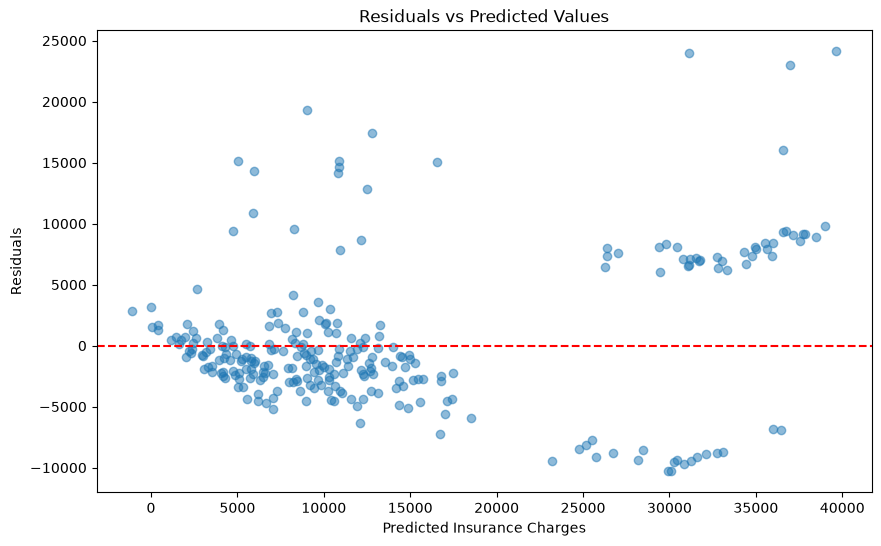

In [50]:
# Predict test values
y_pred = linear_model.predict(X_test)

# Calculate residuals
residuals = y_test - y_pred

# Plot residuals vs predicted values
plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Insurance Charges")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

In [51]:
# Create copies of original datasets
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Feature 1: Smoker × BMI
X_train_fe["smoker_bmi"] = (
    X_train_fe["bmi"] *
    (X_train_fe["smoker"] == "yes").astype(int)
)

X_test_fe["smoker_bmi"] = (
    X_test_fe["bmi"] *
    (X_test_fe["smoker"] == "yes").astype(int)
)

# Feature 2: Age squared
X_train_fe["age_squared"] = X_train_fe["age"] ** 2
X_test_fe["age_squared"] = X_test_fe["age"] ** 2

print(X_train_fe.head())
print("New training shape:", X_train_fe.shape)

      age     sex     bmi  children smoker     region  smoker_bmi  age_squared
1114   23    male  24.510         0     no  northeast         0.0          529
968    21    male  25.745         2     no  northeast         0.0          441
599    52  female  37.525         2     no  northwest         0.0         2704
170    63    male  41.470         0     no  southeast         0.0         3969
275    47  female  26.600         2     no  northeast         0.0         2209
New training shape: (1069, 8)


In [52]:
numeric_features = [
    "age",
    "bmi",
    "children",
    "smoker_bmi",
    "age_squared"
]

categorical_features = [
    "sex",
    "smoker",
    "region"
]

preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), categorical_features)
    ]
)

improved_model = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("regressor", LinearRegression())
])

improved_model.fit(X_train_fe, y_train)

print("Feature engineering model trained!")

Feature engineering model trained!


In [53]:
predictions_fe = improved_model.predict(X_test_fe)

print("MAE:", mean_absolute_error(
    y_test, predictions_fe
))

print("RMSE:", np.sqrt(mean_squared_error(
    y_test, predictions_fe
)))

print("R2:", r2_score(
    y_test, predictions_fe
))

MAE: 2886.667447655273
RMSE: 4585.760384758054
R2: 0.8855591600954574


In [54]:

# Function to train and evaluate feature engineering models

def run_experiment(experiment_name, extra_features=None, log_target=False):

    extra_features = extra_features or []

    Xtr = X_train.copy()
    Xte = X_test.copy()

    # Add interaction feature
    if "smoker_bmi" in extra_features:
        Xtr["smoker_bmi"] = (
            Xtr["bmi"] * (Xtr["smoker"] == "yes").astype(int)
        )
        Xte["smoker_bmi"] = (
            Xte["bmi"] * (Xte["smoker"] == "yes").astype(int)
        )

    # Add age squared
    if "age_squared" in extra_features:
        Xtr["age_squared"] = Xtr["age"] ** 2
        Xte["age_squared"] = Xte["age"] ** 2

    numeric_cols = ["age", "bmi", "children"] + extra_features
    categorical_cols = ["sex", "smoker", "region"]

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), categorical_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    # Train on original or log-transformed target
    target_train = np.log(y_train) if log_target else y_train

    model.fit(Xtr, target_train)

    predictions = model.predict(Xte)

    # Convert log predictions back to dollars
    if log_target:
        predictions = np.exp(predictions)

    return {
        "Experiment": experiment_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }


# Run all experiments
results = []

results.append(run_experiment("Baseline"))

results.append(run_experiment(
    "Smoker x BMI",
    ["smoker_bmi"]
))

results.append(run_experiment(
    "Age Squared",
    ["age_squared"]
))

results.append(run_experiment(
    "Both Features",
    ["smoker_bmi", "age_squared"]
))

results.append(run_experiment(
    "Log Charges",
    ["smoker_bmi", "age_squared"],
    log_target=True
))

# Display comparison table
comparison_q9 = pd.DataFrame(results)

comparison_q9.round(3)


,Experiment,MAE,RMSE,R2
0,Baseline,4177.046,5956.343,0.807
1,Smoker x BMI,2828.974,4572.811,0.886
2,Age Squared,4223.458,6022.932,0.803
3,Both Features,2886.667,4585.760,0.886
4,Log Charges,4242.276,8679.526,0.590


In [55]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [56]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Subtraining shape:", X_subtrain.shape)
print("Validation shape:", X_val.shape)

Subtraining shape: (855, 6)
Validation shape: (214, 6)


In [57]:

numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

polynomial_results = []

for degree in range(1, 7):

    numeric_pipeline = Pipeline([
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("scaler", StandardScaler())
    ])

    preprocessor_poly = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), categorical_features)
    ])

    poly_model = Pipeline([
        ("preprocessor", preprocessor_poly),
        ("regressor", LinearRegression())
    ])

    # Train model
    poly_model.fit(X_subtrain, y_subtrain)

    # Predictions
    train_pred = poly_model.predict(X_subtrain)
    val_pred = poly_model.predict(X_val)

    # Calculate RMSE
    train_rmse = np.sqrt(
        mean_squared_error(y_subtrain, train_pred)
    )

    val_rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    polynomial_results.append({
        "Degree": degree,
        "Train RMSE": train_rmse,
        "Validation RMSE": val_rmse
    })

poly_comparison = pd.DataFrame(polynomial_results)

poly_comparison.round(3)


,Degree,Train RMSE,Validation RMSE
0,1,6139.555,5846.902
1,2,6030.040,5837.239
2,3,5945.927,5952.901
3,4,5901.006,5995.243
4,5,5785.284,6038.669
5,6,5629.014,6647.933


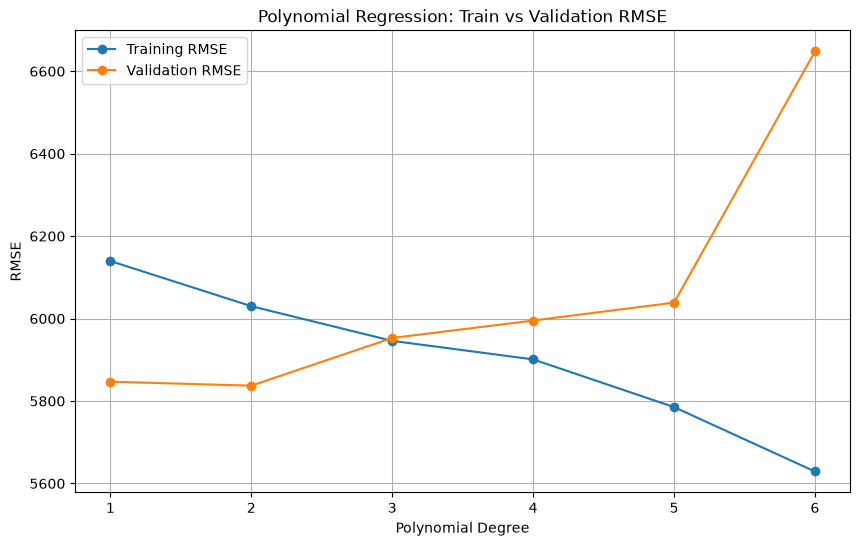

In [58]:
plt.figure(figsize=(10, 6))

plt.plot(
    poly_comparison["Degree"],
    poly_comparison["Train RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    poly_comparison["Degree"],
    poly_comparison["Validation RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE")
plt.title("Polynomial Regression: Train vs Validation RMSE")

plt.xticks(range(1, 7))
plt.legend()
plt.grid(True)

plt.show()

In [59]:
from sklearn.linear_model import RidgeCV, LassoCV

In [60]:
X_train_reg = X_train.copy()
X_test_reg = X_test.copy()

X_train_reg["smoker_bmi"] = (
    X_train_reg["bmi"] *
    (X_train_reg["smoker"] == "yes").astype(int)
)

X_test_reg["smoker_bmi"] = (
    X_test_reg["bmi"] *
    (X_test_reg["smoker"] == "yes").astype(int)
)

numeric_features = [
    "age", "bmi", "children", "smoker_bmi"
]

categorical_features = [
    "sex", "smoker", "region"
]

print("Regularization features prepared!")

Regularization features prepared!


In [61]:
preprocessor_reg = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),

    ("cat", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), categorical_features)
])

In [62]:
alphas = np.logspace(-3, 3, 50)

ridge_model = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("regressor", RidgeCV(
        alphas=alphas,
        cv=5
    ))
])

ridge_model.fit(X_train_reg, y_train)

ridge_alpha = ridge_model.named_steps[
    "regressor"
].alpha_

print("Best Ridge Alpha:", ridge_alpha)

Best Ridge Alpha: 0.09102981779915217


In [63]:
lasso_model = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("regressor", LassoCV(
        alphas=alphas,
        cv=5,
        max_iter=100000
    ))
])

lasso_model.fit(X_train_reg, y_train)

lasso_alpha = lasso_model.named_steps[
    "regressor"
].alpha_

print("Best Lasso Alpha:", lasso_alpha)

Best Lasso Alpha: 0.868511373751352


In [64]:
feature_names = (
    lasso_model.named_steps[
        "preprocessor"
    ].get_feature_names_out()
)

lasso_coefficients = (
    lasso_model.named_steps[
        "regressor"
    ].coef_
)

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lasso_coefficients
})

print("Lasso Coefficients:")
print(coefficient_table.round(4))

zero_features = coefficient_table[
    np.isclose(
        coefficient_table["Coefficient"],
        0,
        atol=1e-6
    )
]

print("\nFeatures set to zero by Lasso:")
print(zero_features)

Lasso Coefficients:
                 Feature  Coefficient
0               num__age    3623.4899
1               num__bmi      81.5147
2          num__children     679.6868
3        num__smoker_bmi   18278.1385
4          cat__sex_male    -641.7057
5        cat__smoker_yes  -21494.1535
6  cat__region_northwest    -423.0449
7  cat__region_southeast    -880.1142
8  cat__region_southwest    -868.3623

Features set to zero by Lasso:
Empty DataFrame
Columns: [Feature, Coefficient]
Index: []


In [65]:
ridge_predictions = ridge_model.predict(X_test_reg)
lasso_predictions = lasso_model.predict(X_test_reg)

regularization_results = pd.DataFrame([
    {
        "Model": "RidgeCV",
        "MAE": mean_absolute_error(
            y_test, ridge_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, ridge_predictions
        )),
        "R2": r2_score(y_test, ridge_predictions)
    },
    {
        "Model": "LassoCV",
        "MAE": mean_absolute_error(
            y_test, lasso_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, lasso_predictions
        )),
        "R2": r2_score(y_test, lasso_predictions)
    }
])

regularization_results.round(3)

,Model,MAE,RMSE,R2
0,RidgeCV,2828.059,4569.763,0.886
1,LassoCV,2828.781,4571.931,0.886


In [66]:
print("Ridge Best Alpha:",
      ridge_model.named_steps["regressor"].alpha_)

print("Lasso Best Alpha:",
      lasso_model.named_steps["regressor"].alpha_)

print("\nComplete Regularization Comparison:")

print(regularization_results.round(3).to_string(index=False))

Ridge Best Alpha: 0.09102981779915217
Lasso Best Alpha: 0.868511373751352

Complete Regularization Comparison:
  Model      MAE     RMSE    R2
RidgeCV 2828.059 4569.763 0.886
LassoCV 2828.781 4571.931 0.886


In [67]:
ridge_regressor = ridge_model.named_steps["regressor"]

feature_names = (
    ridge_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = ridge_regressor.coef_

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_table["Absolute"] = (
    coefficient_table["Coefficient"].abs()
)

top_3 = coefficient_table.sort_values(
    "Absolute",
    ascending=False
).head(3)

print(top_3)

           Feature   Coefficient      Absolute
5  cat__smoker_yes -21298.003611  21298.003611
3  num__smoker_bmi  18200.304770  18200.304770
0         num__age   3623.122862   3623.122862


In [68]:
import joblib

# Save the best trained pipeline
joblib.dump(ridge_model, "../models/medical_insurance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [69]:
def predict_charges(age, sex, bmi, children, smoker, region):

    input_data = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region
    }])

    prediction = ridge_model.predict(input_data)

    return round(float(prediction[0]), 2)

In [72]:

def predict_charges(age, sex, bmi, children, smoker, region):

    input_data = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region
    }])

    # Create the engineered feature
    input_data["smoker_bmi"] = (
        input_data["bmi"] *
        (input_data["smoker"].str.lower() == "yes").astype(int)
    )

    # Predict insurance charges
    prediction = ridge_model.predict(input_data)

    return round(float(prediction[0]), 2)


In [73]:

result = predict_charges(
    age=30,
    sex="male",
    bmi=25.5,
    children=1,
    smoker="no",
    region="southeast"
)

print("Predicted Insurance Charges: $", result)


Predicted Insurance Charges: $ 5267.64


In [74]:
import joblib

joblib.dump(
    ridge_model,
    "../models/medical_insurance_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


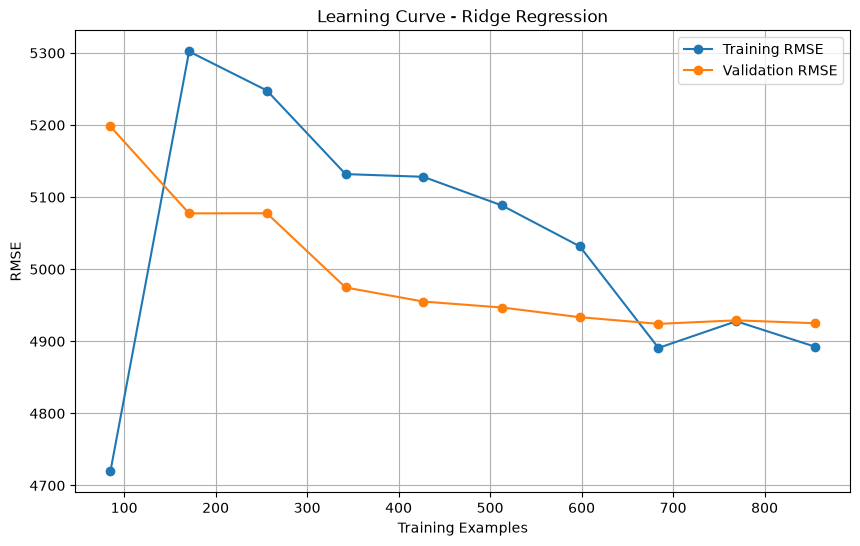

In [75]:

from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

train_sizes, train_scores, validation_scores = learning_curve(
    ridge_model,
    X_train_fe,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

train_rmse = -train_scores.mean(axis=1)
validation_rmse = -validation_scores.mean(axis=1)

plt.figure(figsize=(10, 6))

plt.plot(train_sizes, train_rmse, marker="o",
         label="Training RMSE")

plt.plot(train_sizes, validation_rmse, marker="o",
         label="Validation RMSE")

plt.xlabel("Training Examples")
plt.ylabel("RMSE")
plt.title("Learning Curve - Ridge Regression")
plt.legend()
plt.grid(True)
plt.show()


In [76]:
import joblib

loaded_model = joblib.load(
    "../models/medical_insurance_model.pkl"
)

def predict_charges(age, sex, bmi, children, smoker, region):
    data = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region
    }])

    data["smoker_bmi"] = (
        data["bmi"] * (data["smoker"] == "yes").astype(int)
    )

    return round(float(loaded_model.predict(data)[0]), 2)

In [77]:
print(predict_charges(30, "male", 25.5, 1, "no", "southeast"))

5267.64
